# Fig 2c — Axis Score vs TMB

Scatter plots of TMB / PQC / non-PQC axis scores against log₁₀(TMB):
- Pan-cancer (all cancer types combined)
- Representative cancer types: strong / typical / weak / negative correlation

In [1]:
import os
import socket

import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

mpl.rcParams["pdf.fonttype"] = 42   # editable text in Illustrator/Inkscape
mpl.rcParams["svg.fonttype"] = "none"

In [2]:
hostname = socket.gethostname()
if "scg" in hostname:
    BASE_DIR = "/labs/mwinslow/Karen/protein-master/v2_pancan_batch_corrected"
else:
    BASE_DIR = os.path.expanduser("~/Documents/research/scg/protein-master/v2_pancan_batch_corrected")

DATA_DIR = f"{BASE_DIR}/analysis/01_axis_analysis/bh/axis_sample_scores"
OUT_DIR  = f"{BASE_DIR}/results/figures/main/fig2"
os.makedirs(OUT_DIR, exist_ok=True)
print(f"OUT_DIR: {OUT_DIR}")

OUT_DIR: /Users/karenshih/Documents/research/scg/protein-master/v2_pancan_batch_corrected/results/figures/main/fig2


In [3]:
df_axis = pd.read_parquet(f"{DATA_DIR}/tcga_xena/axis_sample_level.parquet")
df_axis.shape

(9104, 7)

## Plot config

Edit values here to adjust aesthetics globally.

In [4]:
PALETTE = {
    "TMB_axis_score":     "#0072B2",  # blue
    "pqc_axis_score":     "#D55E00",  # vermillion
    "non_pqc_axis_score": "#009E73",  # teal
}

SCORES = ["TMB_axis_score", "pqc_axis_score", "non_pqc_axis_score"]

SCORE_STEMS = {
    "TMB_axis_score":     "tmb_axis",
    "pqc_axis_score":     "pqc_axis",
    "non_pqc_axis_score": "non_pqc_axis",
}

FIGSIZE     = (6, 5)
POINT_SIZE  = 20
POINT_ALPHA = 0.7
ANNOT_POS   = (0.02, 0.9)  # (x, y) in axes-fraction coordinates
ANNOT_SIZE  = 10

# Fixed margins so axes area is identical across all panels
MARGINS = dict(left=0.15, right=0.95, bottom=0.15, top=0.95)

In [5]:
def _padded_lim(series, frac=0.05):
    lo, hi = series.min(), series.max()
    pad = frac * (hi - lo)
    return (lo - pad, hi + pad)

AXIS_LIMITS = {col: _padded_lim(df_axis[col]) for col in ["log_mut"] + SCORES}

## Helper functions

In [6]:
def plot_axis_vs_tmb(df, score, filename):
    """Scatter plot of `score` vs log(TMB). Saves PDF to OUT_DIR."""
    x, y = df["log_mut"], df[score]
    r, p = pearsonr(x, y)
    p_str = "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

    fig, ax = plt.subplots(figsize=FIGSIZE)
    fig.subplots_adjust(**MARGINS)
    sns.scatterplot(
        data=df, x=x, y=y,
        color=PALETTE[score],
        s=POINT_SIZE, alpha=POINT_ALPHA,
        rasterized=True, ax=ax,
    )
    ax.annotate(
        f"r = {r:.2f}\n{p_str}",
        xy=ANNOT_POS, xycoords="axes fraction", fontsize=ANNOT_SIZE,
    )
    ax.set_xlim(*AXIS_LIMITS["log_mut"])
    ax.set_ylim(*AXIS_LIMITS[score])
    ax.set_xlabel("")
    ax.set_ylabel("")
    sns.despine(ax=ax)
    plt.savefig(f"{OUT_DIR}/{filename}.pdf", dpi=300)
    plt.show()
    return r, p


def corr_with_p(df_group, metric):
    result = pearsonr(df_group[metric], df_group["log_mut"])
    ci = result.confidence_interval(confidence_level=0.95)
    return pd.Series({
        "r":       result.statistic,
        "p":       result.pvalue,
        "ci_low":  ci.low,
        "ci_high": ci.high,
    })

## Pan-cancer scatter plots

All cancer types combined.

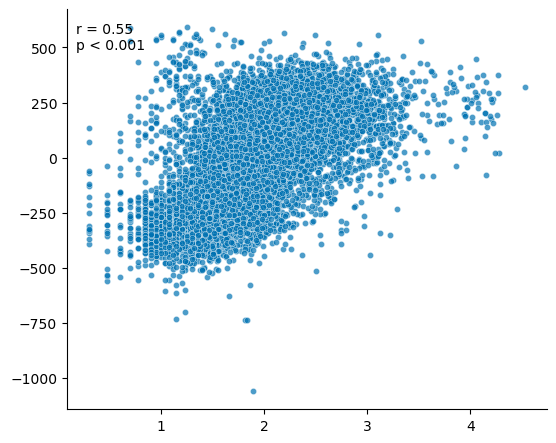

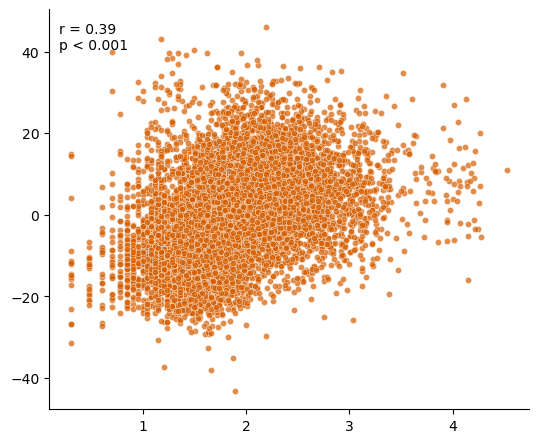

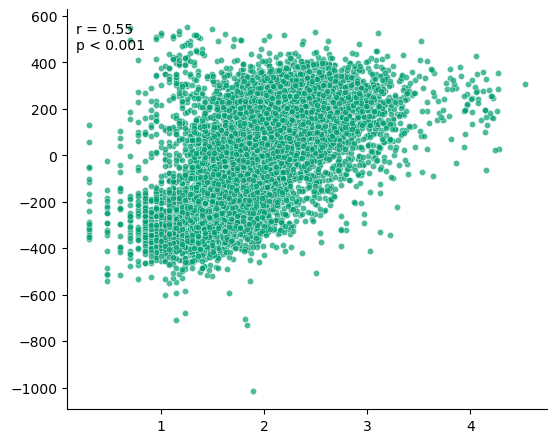

In [7]:
for score in SCORES:
    plot_axis_vs_tmb(df_axis, score, f"pancan_{SCORE_STEMS[score]}")

## Per-cancer-type scatter plots

Select one representative cancer type per correlation-strength tier
(strong / typical / weak / negative), then plot all three scores for each.

In [8]:
corr_df = (
    df_axis
    .groupby("cancer_type")
    .apply(lambda g: corr_with_p(g, "TMB_axis_score"), include_groups=False)
    .reset_index()
)
corr_df.sort_values("r", ascending=False)

,cancer_type,r,p,ci_low,ci_high
25,STAD,0.541203,1.006760e-32,0.469120,0.606122
10,KICH,0.541046,2.728597e-06,0.344070,0.692408
15,LUAD,0.516444,3.507853e-36,0.449855,0.577323
0,ACC,0.495984,3.350494e-06,0.308732,0.646225
30,UCS,0.480967,1.524258e-04,0.251978,0.658952
13,LGG,0.454044,2.090132e-27,0.382435,0.520231
2,BRCA,0.407614,4.998221e-42,0.355065,0.457596
21,PRAD,0.397970,2.844960e-20,0.321180,0.469561
23,SARC,0.381612,1.577251e-09,0.266404,0.486070
1,BLCA,0.372222,8.666320e-15,0.285231,0.453130


In [9]:
def pick_closest(df, target):
    idx = (df["r"] - target).abs().idxmin()
    return df.loc[idx, "cancer_type"]

df_pos = corr_df[corr_df["r"] > 0]
df_neg = corr_df[corr_df["r"] < 0]

representative_types = {
    "strong":   pick_closest(df_pos, df_pos["r"].quantile(0.92)),
    "typical":  pick_closest(df_pos, df_pos["r"].quantile(0.50)),
    "weak":     pick_closest(df_pos, df_pos["r"].quantile(0.10)),
    "negative": pick_closest(df_neg, df_neg["r"].min()),
}
print(representative_types)

{'strong': 'LUAD', 'typical': 'OV', 'weak': 'PCPG', 'negative': 'THYM'}


--- strong: LUAD ---


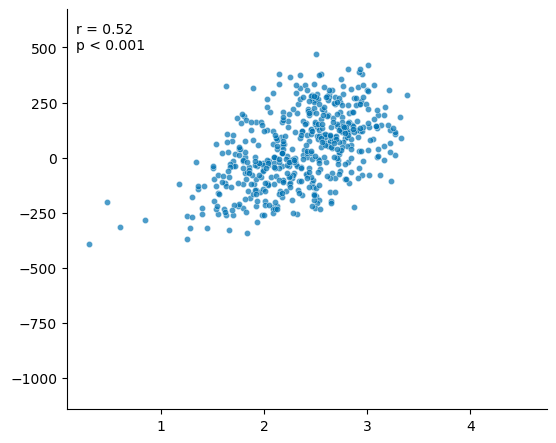

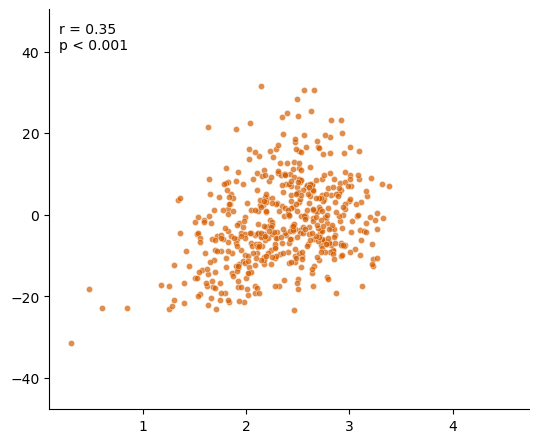

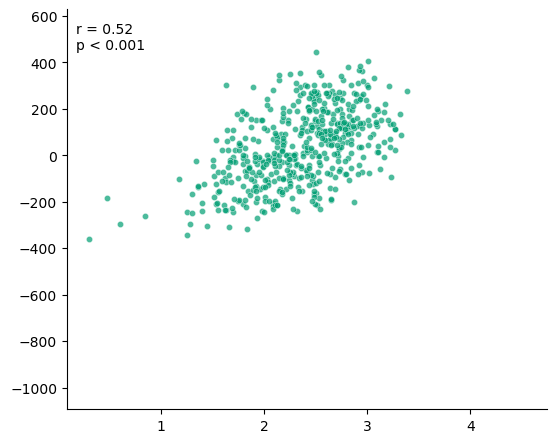

--- typical: OV ---


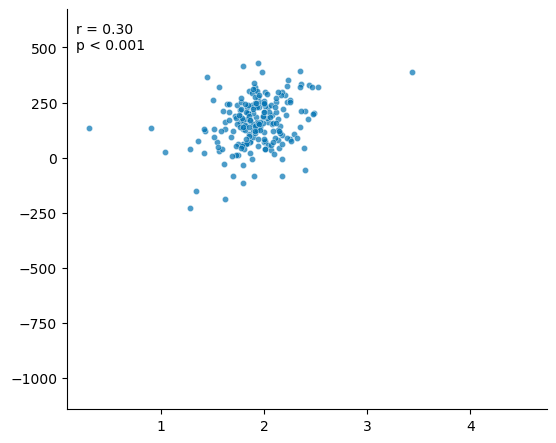

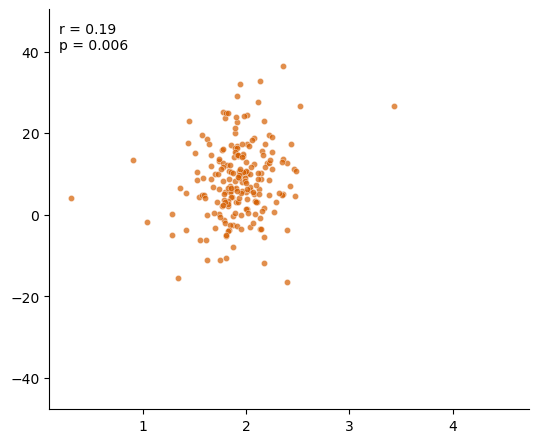

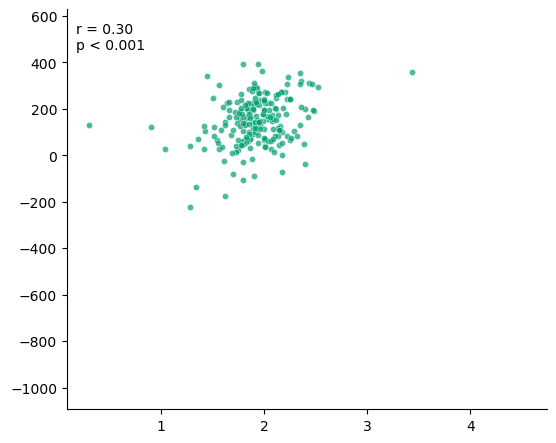

--- weak: PCPG ---


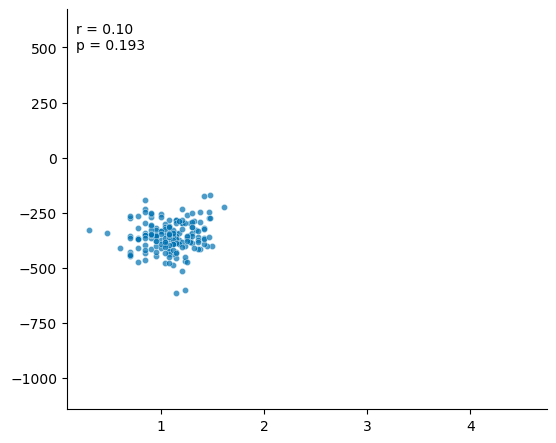

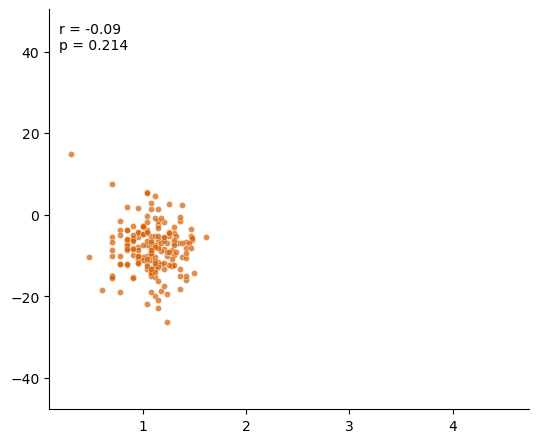

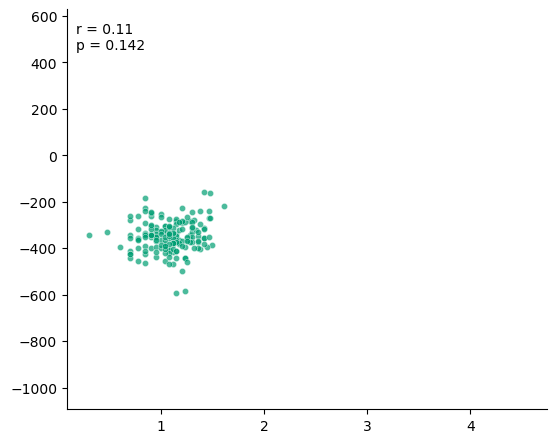

--- negative: THYM ---


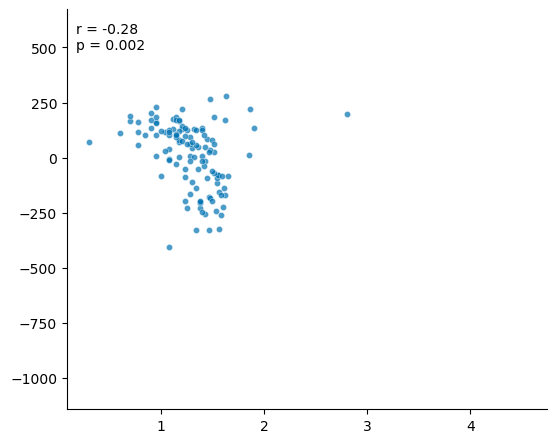

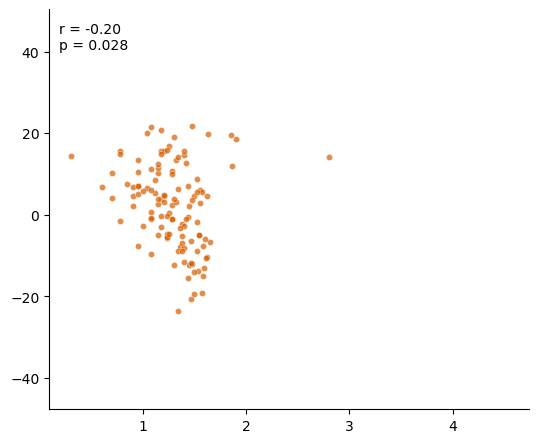

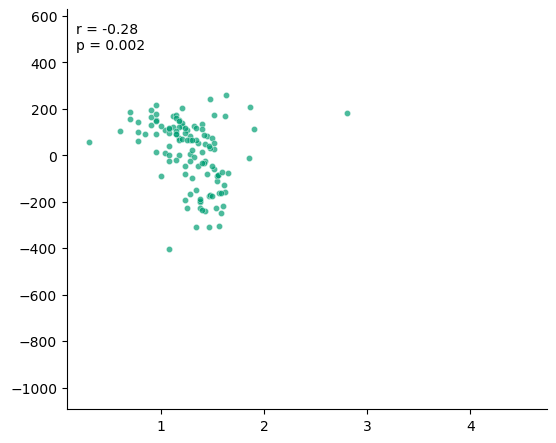

In [10]:
for label, cancer_type in representative_types.items():
    df_sub = df_axis[df_axis["cancer_type"] == cancer_type]
    print(f"--- {label}: {cancer_type} ---")
    for score in SCORES:
        plot_axis_vs_tmb(df_sub, score, f"{cancer_type}_{SCORE_STEMS[score]}")